# Visualize a saved MAPS inverse-design run

This notebook loads the self-contained Tidy3D visualization artifact saved by a completed MAPS run. It contains fixed geometry, the materialized design, and native Tidy3D frames for physical port sources and modal monitors. Auxiliary design-region/full-domain phasor monitors are intentionally omitted.

In [ ]:
import sys
from pathlib import Path

# Allow the notebook to run from the repository root or docs/notebooks/.
search_roots = (Path.cwd(), *Path.cwd().parents)
repo_root = next((path for path in search_roots if (path / "core").is_dir()), None)
if repo_root is None:
    raise RuntimeError("Could not find the MAPS repository root containing core/")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from core.visualization import (
    load_device_visualization_simulation,
    plot_tidy3d_slices,
)

## Load the newest saved device

By default, the cell selects the newest `*.h5` geometry artifact under `runs/bending_3d/`. To inspect a particular run, assign its artifact path to `artifact_path` instead.

In [ ]:
artifact_path = (
    None  # Example: repo_root / 'runs/bending_3d/<run_id>/geometry/<name>.h5'
)

if artifact_path is None:
    artifacts = list(
        (repo_root / "runs" / "grating_coupler_3d").glob("*/geometry/*.h5")
    )
    if not artifacts:
        raise FileNotFoundError("No saved bending_3d geometry artifacts were found")
    artifact_path = max(artifacts, key=lambda path: path.stat().st_mtime)

artifact_path = Path(artifact_path).resolve()
run_dir = artifact_path.parents[1]
print(f"Run:      {run_dir.name}")
print(f"Artifact: {artifact_path}")

saved_bend = load_device_visualization_simulation(artifact_path)
saved_bend.plot_3d()

Run:      20261017T220354Z_grating_coupler_1.31_4x4_autogrid15_sym_new2_sparse3_cbbe8585
Artifact: ./runs/grating_coupler_3d/20261017T220354Z_grating_coupler_1.31_4x4_autogrid15_sym_new2_sparse3_cbbe8585/geometry/grating_coupler_1.31_4x4_autogrid15_sym_new2_sparse3_tidy3d_geometry.h5


15:41:05 MST WARNING: 'filter_pol' is deprecated and will be removed in future  
             versions. Please use 'sort_spec' instead.                          

             WARNING: 'filter_pol' is deprecated and will be removed in future  
             versions. Please use 'sort_spec' instead.                          

## Optional local cross-section

The saved file contains fixed structures, the materialized optimized design region, and physical source/port-monitor planes. A local 2-D slice can be inspected without launching the hosted 3-D viewer.

<Axes: title={'center': 'cross section at z=0.00 (μm)'}, xlabel='x (μm)', ylabel='y (μm)'>

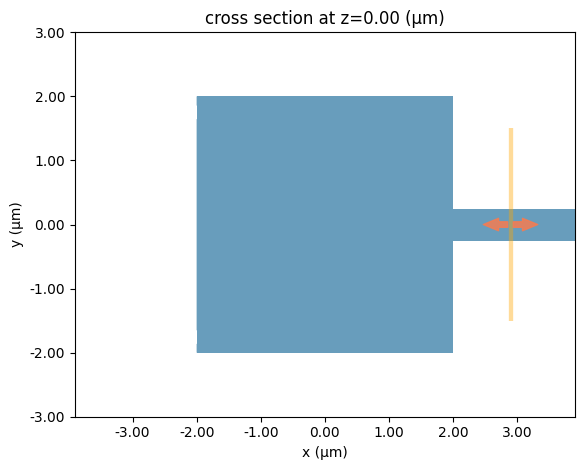

In [ ]:
saved_bend.plot(z=0.0)

## Interactive orthogonal slices

Move the x, y, and z sliders to inspect the YZ, XZ, and XY cross-sections. Redrawing occurs when a slider is released. Expand **Visibility** to independently show or hide each saved structure, all sources, or all monitors across the three native Tidy3D plots. Visibility changes are local to this widget and do not modify the HDF5 artifact.

In [ ]:
plot_tidy3d_slices(saved_bend)

15:41:17 MST WARNING: 'filter_pol' is deprecated and will be removed in future  
             versions. Please use 'sort_spec' instead.                          

             WARNING: 'filter_pol' is deprecated and will be removed in future  
             versions. Please use 'sort_spec' instead.                          

15:41:20 MST WARNING: 'filter_pol' is deprecated and will be removed in future  
             versions. Please use 'sort_spec' instead.                          

             WARNING: 'filter_pol' is deprecated and will be removed in future  
             versions. Please use 'sort_spec' instead.                          

15:41:26 MST WARNING: 'filter_pol' is deprecated and will be removed in future  
             versions. Please use 'sort_spec' instead.                          

             WARNING: 'filter_pol' is deprecated and will be removed in future  
             versions. Please use 'sort_spec' instead.                          

... (30 outputs left out)

15:42:25 MST WARNING: 'filter_pol' is deprecated and will be removed in future  
             versions. Please use 'sort_spec' instead.                          

             WARNING: 'filter_pol' is deprecated and will be removed in future  
             versions. Please use 'sort_spec' instead.                          

15:42:33 MST WARNING: 'filter_pol' is deprecated and will be removed in future  
             versions. Please use 'sort_spec' instead.                          

             WARNING: 'filter_pol' is deprecated and will be removed in future  
             versions. Please use 'sort_spec' instead.                          

## Field data

The source and monitor objects in this artifact are visualization metadata; the file does not contain solved electromagnetic fields. Field visualization can also be load-only once a `SimulationData`/field artifact is saved by the run manager, but loading this device artifact does not recreate fields or execute the solver.